# 02 · Priorização de manutenção e comparação de custos

**Pergunta.** Dadas as RULs previstas para os 100 motores do teste, quais motores devem receber intervenção primeiro, e quando adiar passa a compensar?

**Método.** Quatro critérios → pesos por AHP (três perfis de decisor) → ordenação por TOPSIS → comparação entre perfis → um teste de sensibilidade da transformação da urgência → cenário econômico ilustrativo.

> **Aviso.** Só a urgência vem do modelo (RUL prevista). Criticidade, custo de intervenção e impacto da parada são **índices hipotéticos**, sorteados com semente fixa. Os valores monetários da seção 6 também são hipóteses. Nada aqui descreve uma planta real.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.ahp import ahp_weights
from src.decision import (CRITERIA, BENEFIT_CRITERIA, PROFILE_MATRICES, build_demo_criteria,
                          run_ranking, compare_profiles, urgency_from_rul, URGENCY_HORIZON,
                          DEFAULT_URGENCY_METHOD)
from src.economics import wasted_life_cost, compare_cost_scenarios, break_even_probability

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

pred = pd.read_csv(REPORTS / "test_predictions.csv")   # gerado pelo notebook 01 / python -m src.modeling
print(f"{len(pred)} motores | RUL prevista: mín {pred.rul_pred.min():.0f}, mediana {pred.rul_pred.median():.0f}, máx {pred.rul_pred.max():.0f}")

100 motores | RUL prevista: mín 6, mediana 81, máx 125


## 1. Critérios e escalas

| Critério | Origem | Direção | Como entra |
|---|---|---|---|
| Urgência | **modelo** (RUL prevista) | benefício (maior = mais prioritário) | `1 − RUL / 125`, truncada em [0, 1] |
| Criticidade operacional | hipotético | benefício | inteiro de 1 a 3 |
| Custo de intervenção | hipotético | **custo** (menor = melhor) | índice de 1 a 10 |
| Impacto da parada | hipotético | benefício (maior = mais prioritário) | índice de 1 a 10 |

O TOPSIS trata critérios de custo e de benefício de forma diferente ao definir a solução ideal. Trocar a orientação do custo inverte o ranking, e há um teste automatizado para isso (`tests/test_topsis.py`).

**Por que a urgência vem da RUL prevista e não de uma "probabilidade de falha":** o modelo gera uma estimativa pontual de RUL, que não é uma probabilidade. Usá-la diretamente como indicador de urgência é mais honesto.

In [2]:
criterios = build_demo_criteria(pred)
display(criterios[["unit_nr", "rul_pred", *CRITERIA]].head(8).round(2))

# Os critérios hipotéticos não devem duplicar informação entre si nem com a urgência.
corr = criterios[CRITERIA].corr(method="spearman").round(2)
display(corr)

,unit_nr,rul_pred,urgency,operational_criticality,intervention_cost,downtime_impact
0,1,124.83,0.00,1,9,4
1,2,119.29,0.05,3,2,10
2,3,50.57,0.60,2,9,5
3,4,70.79,0.43,2,1,7
4,5,95.43,0.24,2,8,5
5,6,98.99,0.21,3,8,3
6,7,100.62,0.20,1,8,8
7,8,74.13,0.41,3,7,10


,urgency,operational_criticality,intervention_cost,downtime_impact
urgency,1.00,0.08,0.18,-0.05
operational_criticality,0.08,1.00,0.09,0.02
intervention_cost,0.18,0.09,1.00,0.00
downtime_impact,-0.05,0.02,0.00,1.00


Os três critérios hipotéticos são independentes entre si por construção (correlações próximas de zero), então nenhum deles repete a informação de outro. A urgência só depende da RUL prevista. Em dados reais, custo e impacto de parada costumam estar correlacionados, e isso exigiria revisar os critérios (por exemplo, fundir ou justificar cada um).

## 2. Perfis AHP e consistência

Cada perfil é uma matriz de comparações pareadas (importância relativa entre critérios, escala de Saaty). Os julgamentos são hipóteses de três decisores:
- **Equilibrado:** todos os critérios com a mesma importância.
- **Segurança primeiro:** urgência e criticidade dominam; o custo quase não pesa.
- **Custo primeiro:** o custo de intervenção domina; a urgência pesa pouco.

In [3]:
nomes = {"balanced": "equilibrado", "safety_first": "segurança", "cost_first": "custo"}
linhas = []
for p, m in PROFILE_MATRICES.items():
    r = ahp_weights(m)
    linhas.append({"perfil": nomes[p], **dict(zip(CRITERIA, r["weights"])),
                   "razão de consistência (CR)": r["consistency_ratio"],
                   "CR ≤ 0,10?": r["consistency_acceptable_reference"]})
pesos = pd.DataFrame(linhas).set_index("perfil")
display(pesos.round(3))

,urgency,operational_criticality,intervention_cost,downtime_impact,razão de consistência (CR),"CR ≤ 0,10?"
perfil,,,,,,
equilibrado,0.250,0.250,0.250,0.250,0.000,True
segurança,0.555,0.246,0.057,0.141,0.025,True
custo,0.121,0.220,0.538,0.121,0.008,True


Todas as razões de consistência ficam abaixo de 0,10, o limite de referência usual: os julgamentos não são contraditórios. (O CR do perfil equilibrado é zero porque todos os julgamentos são iguais.)

## 3. Ranking TOPSIS por perfil

In [4]:
rankings = {}
for p in PROFILE_MATRICES:
    r, meta = run_ranking(pred, p)
    rankings[p] = r
    r.to_csv(REPORTS / f"ranking_{p}.csv", index=False)

top10 = pd.DataFrame({
    nomes[p]: rankings[p]["unit_nr"].head(10).to_numpy() for p in PROFILE_MATRICES
}, index=range(1, 11))
top10.index.name = "posição"
display(top10)

,equilibrado,segurança,custo
posição,,,
1,20,20,38
2,42,34,20
3,64,35,4
4,82,49,82
5,34,76,68
6,38,42,70
7,90,82,27
8,36,31,98
9,40,81,57


In [5]:
cmp_ = compare_profiles(pred)
print("Correlação de postos (Spearman) entre perfis:")
display(cmp_["spearman"].rename(index=nomes, columns=nomes).round(2))
print("Motores em comum no top-10 de cada par de perfis:")
display(cmp_["top_k_overlap"].rename(index=nomes, columns=nomes))
prioritarios = cmp_["top_k_in_all_profiles"]
display(Markdown(f"**Motores no top-10 dos três perfis: {prioritarios}.**"))
display(pred[pred.unit_nr.isin(prioritarios)][["unit_nr", "last_observed_cycle", "rul_pred", "rul_true"]].round(1)
        .rename(columns={"rul_true": "rul_real (só para conferência)"}))

Correlação de postos (Spearman) entre perfis:


,equilibrado,segurança,custo
equilibrado,1.00,0.74,0.48
segurança,0.74,1.00,-0.03
custo,0.48,-0.03,1.00


Motores em comum no top-10 de cada par de perfis:


,equilibrado,segurança,custo
equilibrado,10,5,4
segurança,5,10,3
custo,4,3,10


**Motores no top-10 dos três perfis: [20, 68, 82].**

,unit_nr,last_observed_cycle,rul_pred,rul_real (só para conferência)
19,20,184,8.0,16
67,68,187,12.0,8
81,82,162,10.9,9


**Leitura.** Os perfis de segurança e de custo produzem ordenações bem diferentes: priorizar urgência e priorizar custo leva a decisões distintas, e a escolha do perfil é uma decisão de negócio, não técnica. Os poucos motores que aparecem no topo dos três perfis são intervenções robustas à escolha de pesos. Já as posições intermediárias mudam bastante conforme o perfil e não devem ser lidas como ordem rígida.

A coluna de RUL real aparece só para conferir que os motores sempre prioritários são, de fato, motores próximos da falha; o ranking foi calculado apenas com a RUL prevista.

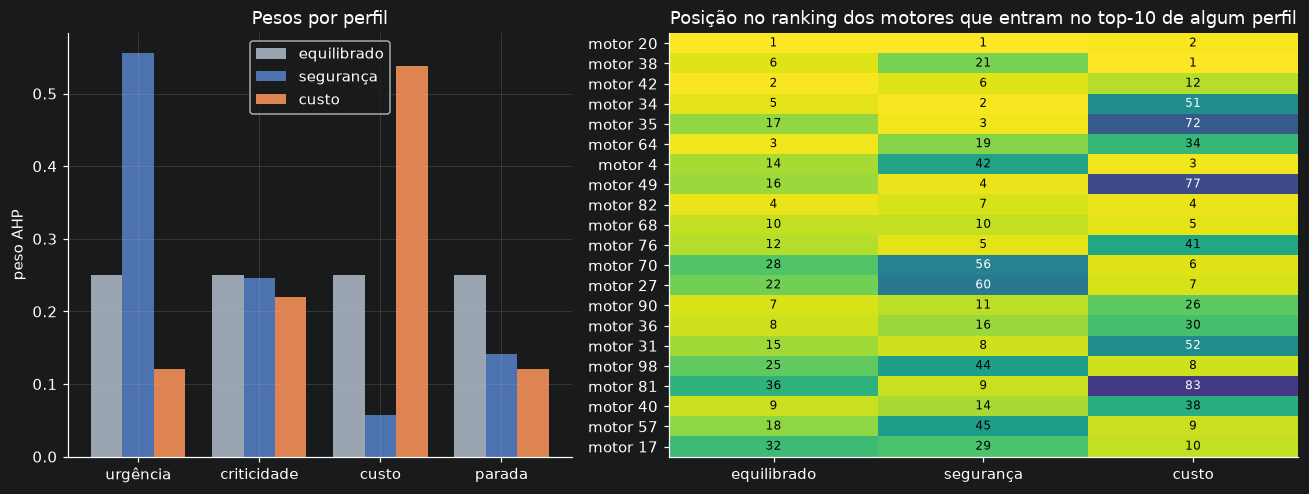

In [6]:
uniao = sorted(set().union(*[set(rankings[p]["unit_nr"].head(10)) for p in PROFILE_MATRICES]))
pos = pd.DataFrame({nomes[p]: rankings[p].set_index("unit_nr")["rank"].reindex(uniao) for p in PROFILE_MATRICES})
pos = pos.loc[pos.min(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]; x = np.arange(len(CRITERIA)); w = 0.26
rot = ["urgência", "criticidade", "custo", "parada"]
for i, (p, cor) in enumerate(zip(PROFILE_MATRICES, ["#9aa5b1", "#4C72B0", "#DD8452"])):
    ax.bar(x + (i - 1) * w, pesos.loc[nomes[p], CRITERIA], w, label=nomes[p], color=cor)
ax.set_xticks(x, rot); ax.set_ylabel("peso AHP"); ax.set_title("Pesos por perfil"); ax.legend()

ax = axes[1]
im = ax.imshow(pos.to_numpy(), cmap="viridis_r", aspect="auto", vmin=1, vmax=100)
ax.set_xticks(range(3), pos.columns); ax.set_yticks(range(len(pos)), [f"motor {u}" for u in pos.index])
for i in range(pos.shape[0]):
    for j in range(pos.shape[1]):
        v = pos.iloc[i, j]
        ax.text(j, i, int(v), ha="center", va="center", fontsize=8, color="white" if v > 45 else "black")
ax.grid(False); ax.set_title("Posição no ranking dos motores que entram no top-10 de algum perfil")
fig.tight_layout(); fig.savefig(FIG / "05_ranking_perfis.png", bbox_inches="tight"); plt.show()

## 4. Sensibilidade: como transformar a RUL em urgência

A transformação da RUL em urgência é uma escolha de modelagem. Comparo a usada (linear em relação a um horizonte de 125 ciclos) com uma alternativa (`1 / (1 + RUL)`, que concentra os valores perto de zero).

In [7]:
lin = compare_profiles(pred, "linear")["scores"]
inv = compare_profiles(pred, "inverse")["scores"]
sens = pd.DataFrame({
    "correlação de postos": {nomes[p]: lin[p].corr(inv[p], method="spearman") for p in lin},
    "motores em comum no top-10": {nomes[p]: len(set(lin[p].nlargest(10).index) & set(inv[p].nlargest(10).index)) for p in lin},
})
display(sens.round(2))
display(Markdown(
    f"Motores no top-10 dos três perfis com urgência **linear**: {compare_profiles(pred,'linear')['top_k_in_all_profiles']}; "
    f"com urgência **inversa**: {compare_profiles(pred,'inverse')['top_k_in_all_profiles']}."
))

,correlação de postos,motores em comum no top-10
equilibrado,0.88,6
segurança,0.82,8
custo,0.99,8


Motores no top-10 dos três perfis com urgência **linear**: [20, 68, 82]; com urgência **inversa**: [20, 68, 82].

**Decisão.** Mantive a transformação **linear**: ela tem interpretação direta (fração do horizonte de planejamento já consumida) e não depende de uma função que concentra quase toda a diferença em motores com RUL próxima de zero. A alternativa muda as posições intermediárias, principalmente no perfil equilibrado, o que confirma que o ranking detalhado depende dessa escolha; os motores de topo comuns aos perfis permanecem os mesmos nas duas versões. Como o horizonte de 125 ciclos também é uma escolha, ele deveria ser definido junto com quem planeja a manutenção.

## 5. Cenário econômico ilustrativo: intervir agora ou adiar?

**Lógica.**
- *Intervir agora* custa a intervenção, a parada planejada e a **vida útil desperdiçada** (a parte da RUL que o componente ainda teria).
- *Adiar* custa a intervenção e a parada (depois), mais a **falha não planejada** se ela ocorrer antes: probabilidade `p` × custo da falha.
- Ponto de equilíbrio: `p* = vida desperdiçada / custo da falha`. Se a chance de falhar antes da intervenção for menor que `p*`, adiar custa menos, nas premissas abaixo.

**Premissas hipotéticas (unidades monetárias fictícias, u.m.):** intervenção 100, parada 50, valor do componente 400 (vida desperdiçada proporcional à RUL em relação a 125 ciclos). O custo da falha varia entre 1000, 2000 e 4000. Não há dados de custo real.

In [8]:
INTERVENCAO, PARADA, VALOR_COMPONENTE = 100.0, 50.0, 400.0
FALHAS = [1000.0, 2000.0, 4000.0]

top1 = rankings["balanced"].iloc[0]
exemplos = {
    f"motor mais prioritário (equilibrado): motor {int(top1.unit_nr)}": float(top1.rul_pred),
    "motor com RUL mediana": float(pred.rul_pred.median()),
    "motor com RUL alta (percentil 90)": float(pred.rul_pred.quantile(0.9)),
}
linhas = []
for nome, rul in exemplos.items():
    wl = wasted_life_cost(rul, VALOR_COMPONENTE, URGENCY_HORIZON)
    linha = {"exemplo": nome, "RUL prevista": round(rul, 1), "vida desperdiçada (u.m.)": round(wl, 1)}
    for f in FALHAS:
        linha[f"p* (falha = {int(f)})"] = round(break_even_probability(wl, f), 3)
    linhas.append(linha)
tab_eq = pd.DataFrame(linhas).set_index("exemplo")
display(tab_eq)

,RUL prevista,vida desperdiçada (u.m.),p* (falha = 1000),p* (falha = 2000),p* (falha = 4000)
exemplo,,,,,
motor mais prioritário (equilibrado): motor 20,8.0,25.5,0.026,0.013,0.006
motor com RUL mediana,81.0,259.1,0.259,0.130,0.065
motor com RUL alta (percentil 90),119.4,382.2,0.382,0.191,0.096


In [9]:
# Exemplo numérico: motor de RUL mediana, falha = 2000 u.m., p = 5% e p = 20%.
rul_ex = float(pred.rul_pred.median())
wl_ex = wasted_life_cost(rul_ex, VALOR_COMPONENTE, URGENCY_HORIZON)
for p in (0.05, 0.20):
    print(f"p = {p:.0%}")
    display(compare_cost_scenarios(INTERVENCAO, PARADA, 2000.0, p, wl_ex).set_index("scenario").round(1))

p = 5%


,intervention_cost,downtime_cost,wasted_life_cost,expected_failure_cost,total_cost
scenario,,,,,
intervene_now,100.0,50.0,259.1,0.0,409.1
delay_intervention,100.0,50.0,0.0,100.0,250.0


p = 20%


,intervention_cost,downtime_cost,wasted_life_cost,expected_failure_cost,total_cost
scenario,,,,,
intervene_now,100.0,50.0,259.1,0.0,409.1
delay_intervention,100.0,50.0,0.0,400.0,550.0


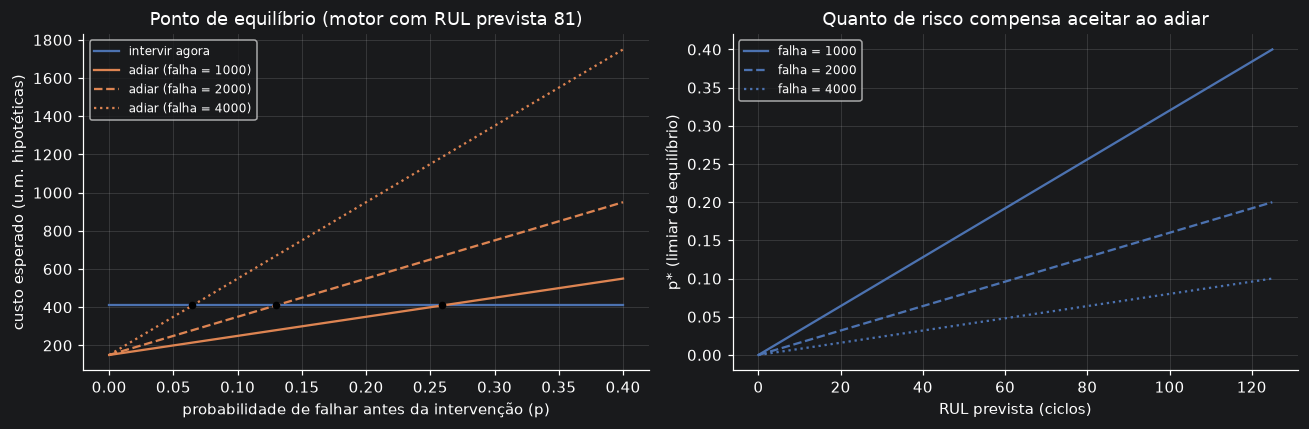

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ps = np.linspace(0, 0.4, 100)
ax = axes[0]
base = INTERVENCAO + PARADA
ax.plot(ps, np.full_like(ps, base + wl_ex), label="intervir agora", color="#4C72B0")
for f, ls in zip(FALHAS, ["-", "--", ":"]):
    ax.plot(ps, base + ps * f, ls=ls, color="#DD8452", label=f"adiar (falha = {int(f)})")
    pstar = break_even_probability(wl_ex, f)
    if pstar <= 0.4:
        ax.plot([pstar], [base + wl_ex], "o", color="black", ms=4)
ax.set(xlabel="probabilidade de falhar antes da intervenção (p)", ylabel="custo esperado (u.m. hipotéticas)",
       title=f"Ponto de equilíbrio (motor com RUL prevista {rul_ex:.0f})"); ax.legend(fontsize=8)

ax = axes[1]
ruls = np.linspace(0, URGENCY_HORIZON, 100)
for f, ls in zip(FALHAS, ["-", "--", ":"]):
    ax.plot(ruls, [break_even_probability(wasted_life_cost(r, VALOR_COMPONENTE, URGENCY_HORIZON), f) for r in ruls],
            ls=ls, color="#4C72B0", label=f"falha = {int(f)}")
ax.set(xlabel="RUL prevista (ciclos)", ylabel="p* (limiar de equilíbrio)",
       title="Quanto de risco compensa aceitar ao adiar"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "06_ponto_equilibrio.png", bbox_inches="tight"); plt.show()

**Leitura.** Quanto maior a RUL prevista, mais vida útil se desperdiça ao intervir agora e maior o limiar `p*`: para motores saudáveis, adiar é razoável mesmo com chance moderada de falha. Quanto mais cara a falha, menor o limiar e mais cedo compensa intervir. Para o motor mais prioritário, `p*` é quase zero: intervir agora é a decisão natural, o que é coerente com o ranking.

**Limites do exercício.** Os valores são fictícios; o modelo de custo é simplificado (um único adiamento, sem desconto no tempo e sem efeito de ocupar equipe); e a probabilidade `p` não foi estimada: o modelo gera uma RUL pontual. Estimar `p` exigiria uma estimativa de incerteza validada (por exemplo, a partir dos resíduos da validação cruzada), o que fica como extensão.

## 6. Conclusões

1. Três perfis de decisor, todos com julgamentos consistentes (CR < 0,10), levam a ordenações diferentes: o perfil importa tanto quanto o modelo.
2. Há motores que lideram o ranking em qualquer perfil e podem ser tratados como prioridade robusta; as posições intermediárias dependem de pesos e da transformação da urgência.
3. O cenário econômico mostra o raciocínio de decisão (limiar de equilíbrio), não um valor financeiro real.
4. **Limitações:** critérios de decisão hipotéticos, dados simulados, RUL pontual sem incerteza, e três perfis de decisor inventados. Em uso real, os pesos viriam de especialistas e os custos de dados da operação.